In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [50]:
X_train = pd.read_csv("data/cleaned/X_train_scaled.csv")
y_train = pd.read_csv("data/cleaned/y_train.csv")
X_val = pd.read_csv("data/cleaned/X_val_scaled.csv")
y_val = pd.read_csv("data/cleaned/y_val.csv")
test_df = pd.read_csv("data/cleaned/test_df.csv")

In [51]:
X_train.head()

,Unnamed: 0,Marital status,Application mode,Application order,Course,Previous qualification,Previous qualification (grade),Mother's qualification,Father's qualification,Mother's occupation,...,Scholarship holder,Age at enrollment,Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade)
0,2930,-0.288731,-0.076465,-0.558954,0.391673,-0.351240,-0.431623,-1.051856,-1.254494,-0.372292,...,-0.589618,-0.678920,-0.107284,-2.015935,-1.537585,-2.209834,-0.099064,-2.053900,-1.465463,-1.960188
1,527,-0.288731,-0.076465,-0.558954,0.441428,-0.351240,3.320607,-1.116316,-1.385174,4.243212,...,1.696013,-0.678920,-0.107284,-0.557906,0.422846,1.030973,-0.099064,-0.511815,0.521190,0.691171
2,1342,-0.288731,1.187659,-0.558954,-0.408271,-0.351240,0.026149,-1.180777,-0.209049,-0.220964,...,1.696013,0.503715,-0.107284,1.872141,-1.210847,-0.141234,-0.099064,1.287285,-1.465463,-1.960188
3,2046,-0.288731,1.474960,-0.558954,0.130821,3.349296,-0.206489,-1.180777,-1.254494,-0.069636,...,1.696013,-0.284708,-0.107284,1.143127,-0.557369,0.341439,-0.099064,1.030271,-1.134354,0.531450
4,2890,-0.288731,-0.076465,-0.558954,0.125508,-0.351240,-0.131444,-1.180777,-1.254494,-0.069636,...,-0.589618,-0.416112,-0.512345,-0.314901,-0.230631,0.272486,-0.551873,0.002214,-0.803245,0.435618


In [52]:
y_train.head()

,Unnamed: 0,Target
0,2930,0
1,527,2
2,1342,0
3,2046,0
4,2890,1


In [53]:
X_train = X_train.drop(columns=["Unnamed: 0"], errors="ignore")
X_val = X_val.drop(columns=["Unnamed: 0"], errors="ignore")

y_train = y_train.drop(columns=["Unnamed: 0"], errors="ignore")
y_val = y_val.drop(columns=["Unnamed: 0"], errors="ignore")

test_ids = test_df["Student_ID"].copy()

X_test = test_df.drop(
    columns=["Unnamed: 0", "Student_ID"],
    errors="ignore"
)

# Samakan urutan dan kolom validasi dengan training
X_val = X_val[X_train.columns]
X_test = X_test[X_train.columns]

In [54]:
print("X_train columns:", len(X_train.columns))
print("X_test columns:", len(X_test.columns))

print("\nKolom yang hanya ada di X_test:")
print(set(X_test.columns) - set(X_train.columns))

print("\nKolom yang hanya ada di X_train:")
print(set(X_train.columns) - set(X_test.columns))

X_train columns: 25
X_test columns: 25

Kolom yang hanya ada di X_test:
set()

Kolom yang hanya ada di X_train:
set()


In [55]:
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (2322, 25)
X_val: (774, 25)
X_test: (1328, 25)


In [56]:
# Ubah ke numpy
X_train = X_train.values.astype(float)
X_val = X_val.values.astype(float)
X_test = X_test.values.astype(float)

In [57]:
classes = sorted(y_train["Target"].unique())

label_to_idx = {label: idx for idx, label in enumerate(classes)}
idx_to_label = {idx: label for label, idx in label_to_idx.items()}  

In [58]:
y_train_idx = y_train['Target'].map(label_to_idx).values
y_val_idx = y_val['Target'].map(label_to_idx).values

In [59]:
num_classes = len(classes)
y_train_oh = np.eye(num_classes)[y_train_idx]
y_val_oh = np.eye(num_classes)[y_val_idx]

In [60]:
print(f"Classes mapping : {label_to_idx}")
print(f"X_train shape   : {X_train.shape}, y_train_oh shape: {y_train_oh.shape}")
print(f"X_val shape     : {X_val.shape}, y_val_oh shape  : {y_val_oh.shape}")

Classes mapping : {np.int64(0): 0, np.int64(1): 1, np.int64(2): 2}
X_train shape   : (2322, 25), y_train_oh shape: (2322, 3)
X_val shape     : (774, 25), y_val_oh shape  : (774, 3)


In [61]:
class Activations:
    @staticmethod
    def relu(Z):
        return np.maximum(0, Z)

    @staticmethod
    def relu_derivative(Z):
        return (Z > 0).astype(np.float64)

    @staticmethod
    def leaky_relu(Z, alpha=0.01):
        return np.where(Z > 0, Z, alpha * Z)

    @staticmethod
    def leaky_relu_derivative(Z, alpha=0.01):
        return np.where(Z > 0, 1.0, alpha)

    @staticmethod
    def sigmoid(Z):
        Z_clipped = np.clip(Z, -500, 500)
        return 1.0 / (1.0 + np.exp(-Z_clipped))

    @staticmethod
    def sigmoid_derivative(Z):
        s = Activations.sigmoid(Z)
        return s * (1.0 - s)

    @staticmethod
    def tanh(Z):
        return np.tanh(Z)

    @staticmethod
    def tanh_derivative(Z):
        return 1.0 - np.tanh(Z) ** 2

    @staticmethod
    def softmax(Z):
        Z_shifted = Z - np.max(Z, axis=1, keepdims=True)
        exp_Z = np.exp(Z_shifted)
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

In [62]:
class ArtificialNeuralNetwork:
    def __init__(
        self,
        input_dim,
        hidden_layers=(64, 32),
        output_dim=3,
        activations='relu',
        learning_rate=0.001,
        epochs=100,
        batch_size=32,
        l2_lambda=0.0,
        random_state=42
    ):
        self.input_dim = input_dim
        self.hidden_layers = list(hidden_layers)
        self.output_dim = output_dim
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.l2_lambda = l2_lambda
        self.random_state = random_state
        if isinstance(activations, str):
            self.activations = [activations.lower()] * len(self.hidden_layers)
        else:
            if len(activations) != len(self.hidden_layers):
                raise ValueError("Length of activations must match number of hidden layers.")
            self.activations = [act.lower() for act in activations]
        self.layer_dims = [self.input_dim] + self.hidden_layers + [self.output_dim]
        self.num_layers = len(self.layer_dims) - 1  # Number of weight matrices
        self.weights = {}
        self.biases = {}
        self.history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
        self._initialize_parameters()

    def _initialize_parameters(self):
        rng = np.random.default_rng(self.random_state)
        for l in range(1, self.num_layers + 1):
            in_dim = self.layer_dims[l - 1]
            out_dim = self.layer_dims[l]

            if l <= len(self.activations) and self.activations[l - 1] in ('relu', 'leaky_relu'):
                std = np.sqrt(2.0 / in_dim)
            else:
                std = np.sqrt(1.0 / in_dim)

            self.weights[l] = rng.normal(0.0, std, size=(in_dim, out_dim))
            self.biases[l] = np.zeros((1, out_dim), dtype=np.float64)

    def _apply_activation(self, Z, name):
        if name == 'relu':
            return Activations.relu(Z)
        elif name == 'leaky_relu':
            return Activations.leaky_relu(Z)
        elif name == 'sigmoid':
            return Activations.sigmoid(Z)
        elif name == 'tanh':
            return Activations.tanh(Z)
        elif name == 'softmax':
            return Activations.softmax(Z)
        else:
            raise ValueError(f"Unsupported activation function: {name}")

    def _apply_activation_derivative(self, Z, name):
        if name == 'relu':
            return Activations.relu_derivative(Z)
        elif name == 'leaky_relu':
            return Activations.leaky_relu_derivative(Z)
        elif name == 'sigmoid':
            return Activations.sigmoid_derivative(Z)
        elif name == 'tanh':
            return Activations.tanh_derivative(Z)
        else:
            raise ValueError(f"Unsupported activation derivative: {name}")

    def forward(self, X):
        """Perform forward propagation across all layers and cache intermediate values."""
        cache = {'A0': X}
        A = X
        for l in range(1, self.num_layers):
            Z = A @ self.weights[l] + self.biases[l]
            A = self._apply_activation(Z, self.activations[l - 1])
            cache[f'Z{l}'] = Z
            cache[f'A{l}'] = A
        L = self.num_layers
        ZL = A @ self.weights[L] + self.biases[L]
        AL = Activations.softmax(ZL)
        cache[f'Z{L}'] = ZL
        cache[f'A{L}'] = AL
        return AL, cache

    def compute_loss(self, y_true_oh, y_pred_probs):
        m = y_true_oh.shape[0]
        eps = 1e-12
        probs_clipped = np.clip(y_pred_probs, eps, 1.0 - eps)
        ce_loss = -np.sum(y_true_oh * np.log(probs_clipped)) / m
        if self.l2_lambda > 0:
            l2_cost = (self.l2_lambda / (2 * m)) * sum(
                np.sum(np.square(self.weights[l])) for l in range(1, self.num_layers + 1)
            )
            return ce_loss + l2_cost
        return ce_loss

    def backward(self, y_true_oh, cache):
        m = y_true_oh.shape[0]
        grads_W = {}
        grads_b = {}
        L = self.num_layers
        dZ = (cache[f'A{L}'] - y_true_oh) / m
        grads_W[L] = cache[f'A{L - 1}'].T @ dZ + (self.l2_lambda / m) * self.weights[L]
        grads_b[L] = np.sum(dZ, axis=0, keepdims=True)
        for l in range(L - 1, 0, -1):
            dA = dZ @ self.weights[l + 1].T
            dZ = dA * self._apply_activation_derivative(cache[f'Z{l}'], self.activations[l - 1])
            grads_W[l] = cache[f'A{l - 1}'].T @ dZ + (self.l2_lambda / m) * self.weights[l]
            grads_b[l] = np.sum(dZ, axis=0, keepdims=True)

        return grads_W, grads_b

    def _update_parameters(self, grads_W, grads_b):
        for l in range(1, self.num_layers + 1):
            self.weights[l] -= self.learning_rate * grads_W[l]
            self.biases[l] -= self.learning_rate * grads_b[l]

    def fit(self, X_train, y_train_oh, X_val=None, y_val_oh=None, verbose=True,patience=15,monitor="val_loss",min_delta=1e-4):
        rng = np.random.default_rng(self.random_state)
        n_samples = X_train.shape[0]
        for epoch in range(1, self.epochs + 1):
            # Shuffle training data each epoch
            indices = rng.permutation(n_samples)
            X_shuffled = X_train[indices]
            y_shuffled = y_train_oh[indices]
            for start in range(0, n_samples, self.batch_size):
                end = start + self.batch_size
                X_batch = X_shuffled[start:end]
                y_batch = y_shuffled[start:end]
                _, cache = self.forward(X_batch)
                grads_W, grads_b = self.backward(y_batch, cache)
                self._update_parameters(grads_W, grads_b)
            train_probs, _ = self.forward(X_train)
            train_loss = self.compute_loss(y_train_oh, train_probs)
            train_acc = np.mean(np.argmax(train_probs, axis=1) == np.argmax(y_train_oh, axis=1))
            self.history['train_loss'].append(train_loss)
            self.history['train_acc'].append(train_acc)
            if X_val is not None and y_val_oh is not None:
                val_probs, _ = self.forward(X_val)
                val_loss = self.compute_loss(y_val_oh, val_probs)
                val_acc = np.mean(np.argmax(val_probs, axis=1) == np.argmax(y_val_oh, axis=1))
                self.history['val_loss'].append(val_loss)
                self.history['val_acc'].append(val_acc)
                if verbose and (epoch % 10 == 0 or epoch == 1 or epoch == self.epochs):
                    print(
                        f"Epoch {epoch:3d}/{self.epochs} | "
                        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
                        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
                    )
            else:
                if verbose and (epoch % 10 == 0 or epoch == 1 or epoch == self.epochs):
                    print(
                        f"Epoch {epoch:3d}/{self.epochs} | "
                        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}"
                    )
        return self

    def predict_proba(self, X):
        probs, _ = self.forward(X)
        return probs

    def predict(self, X):
        probs = self.predict_proba(X)
        return np.argmax(probs, axis=1)

In [63]:
def gradient_check(model, X_sample, y_sample_oh, epsilon=1e-7):
    _, cache = model.forward(X_sample)
    grads_W, grads_b = model.backward(y_sample_oh, cache)

    for l in range(1, model.num_layers + 1):
        W = model.weights[l]
        dW_num = np.zeros_like(W)
        it = np.nditer(W, flags=['multi_index'], op_flags=['readwrite'])
        while not it.finished:
            idx = it.multi_index
            orig = W[idx]

            W[idx] = orig + epsilon
            p_plus, _ = model.forward(X_sample)
            loss_plus = model.compute_loss(y_sample_oh, p_plus)

            W[idx] = orig - epsilon
            p_minus, _ = model.forward(X_sample)
            loss_minus = model.compute_loss(y_sample_oh, p_minus)

            dW_num[idx] = (loss_plus - loss_minus) / (2 * epsilon)
            W[idx] = orig
            it.iternext()
        rel_error = np.linalg.norm(grads_W[l] - dW_num) / (
            np.linalg.norm(grads_W[l]) + np.linalg.norm(dW_num) + 1e-12
        )
        print(f"Layer {l} Weights Relative Gradient Error: {rel_error:.2e}")

In [64]:
test_nn = ArtificialNeuralNetwork(
    input_dim=X_train.shape[1],
    hidden_layers=(8, 6),
    output_dim=num_classes,
    activations=['relu', 'tanh'],
    l2_lambda=0.01
)
gradient_check(test_nn, X_train[:5], y_train_oh[:5])

Layer 1 Weights Relative Gradient Error: 3.40e-09
Layer 2 Weights Relative Gradient Error: 2.24e-09
Layer 3 Weights Relative Gradient Error: 3.11e-09


In [ ]:
ann_relu = ArtificialNeuralNetwork(
    input_dim=X_train.shape[1],
    hidden_layers=(64, 32),
    output_dim=num_classes,
    activations="relu",
    learning_rate=0.005,
    epochs=100,
    batch_size=32,
    l2_lambda=0.001,
    random_state=42
)

print("--- Training ANN with ReLU ---")

ann_relu.fit(
    X_train,
    y_train_oh,
    X_val,
    y_val_oh,
    verbose=True,
    patience=20,
    monitor="val_loss"
)


--- Training ANN with ReLU ---
Epoch   1/200 | Train Loss: 0.8626 | Train Acc: 0.6494 | Val Loss: 0.8849 | Val Acc: 0.6331
Epoch  10/200 | Train Loss: 0.6383 | Train Acc: 0.7399 | Val Loss: 0.6569 | Val Acc: 0.7132


Epoch  20/200 | Train Loss: 0.5942 | Train Acc: 0.7545 | Val Loss: 0.6257 | Val Acc: 0.7339
Epoch  30/200 | Train Loss: 0.5719 | Train Acc: 0.7653 | Val Loss: 0.6141 | Val Acc: 0.7532
Epoch  40/200 | Train Loss: 0.5564 | Train Acc: 0.7713 | Val Loss: 0.6070 | Val Acc: 0.7584
Epoch  50/200 | Train Loss: 0.5439 | Train Acc: 0.7773 | Val Loss: 0.6043 | Val Acc: 0.7584
Epoch  60/200 | Train Loss: 0.5321 | Train Acc: 0.7821 | Val Loss: 0.6014 | Val Acc: 0.7597
Epoch  70/200 | Train Loss: 0.5215 | Train Acc: 0.7894 | Val Loss: 0.5986 | Val Acc: 0.7623
Epoch  80/200 | Train Loss: 0.5119 | Train Acc: 0.7946 | Val Loss: 0.5976 | Val Acc: 0.7545
Epoch  90/200 | Train Loss: 0.5025 | Train Acc: 0.8015 | Val Loss: 0.5988 | Val Acc: 0.7558
Epoch 100/200 | Train Loss: 0.4934 | Train Acc: 0.8075 | Val Loss: 0.5995 | Val Acc: 0.7571
Epoch 110/200 | Train Loss: 0.4850 | Train Acc: 0.8114 | Val Loss: 0.6016 | Val Acc: 0.7558
Epoch 120/200 | Train Loss: 0.4772 | Train Acc: 0.8161 | Val Loss: 0.6075 | Val 

In [66]:
import joblib
joblib.dump(ann_relu, "../output/ann_relu_model.pkl")

['../output/ann_relu_model.pkl']

In [67]:
# Train comparison ANN model (Tanh hidden layers)
ann_tanh = ArtificialNeuralNetwork(
    input_dim=X_train.shape[1],
    hidden_layers=(64, 32),
    output_dim=num_classes,
    activations='tanh',
    learning_rate=0.02,
    epochs=100,
    batch_size=32,
    l2_lambda=0.01,
    random_state=42
)
print("\n--- Training ANN with Tanh ---")
ann_tanh.fit(X_train, y_train_oh, X_val, y_val_oh, verbose=True)


--- Training ANN with Tanh ---
Epoch   1/100 | Train Loss: 0.6981 | Train Acc: 0.7278 | Val Loss: 0.7037 | Val Acc: 0.7261
Epoch  10/100 | Train Loss: 0.5726 | Train Acc: 0.7683 | Val Loss: 0.5830 | Val Acc: 0.7403
Epoch  20/100 | Train Loss: 0.5480 | Train Acc: 0.7778 | Val Loss: 0.5734 | Val Acc: 0.7532
Epoch  30/100 | Train Loss: 0.5298 | Train Acc: 0.7881 | Val Loss: 0.5713 | Val Acc: 0.7481
Epoch  40/100 | Train Loss: 0.5132 | Train Acc: 0.7941 | Val Loss: 0.5723 | Val Acc: 0.7481
Epoch  50/100 | Train Loss: 0.4970 | Train Acc: 0.8058 | Val Loss: 0.5709 | Val Acc: 0.7532
Epoch  60/100 | Train Loss: 0.4807 | Train Acc: 0.8122 | Val Loss: 0.5686 | Val Acc: 0.7545
Epoch  70/100 | Train Loss: 0.4643 | Train Acc: 0.8217 | Val Loss: 0.5714 | Val Acc: 0.7545
Epoch  80/100 | Train Loss: 0.4500 | Train Acc: 0.8286 | Val Loss: 0.5793 | Val Acc: 0.7519
Epoch  90/100 | Train Loss: 0.4320 | Train Acc: 0.8325 | Val Loss: 0.5859 | Val Acc: 0.7610
Epoch 100/100 | Train Loss: 0.4130 | Train Acc: 

In [68]:
# Train comparison ANN model (Sigmoid hidden layers)
ann_sigmoid = ArtificialNeuralNetwork(
    input_dim=X_train.shape[1],
    hidden_layers=(64, 32),
    output_dim=num_classes,
    activations='sigmoid',
    learning_rate=0.05,
    epochs=100,
    batch_size=32,
    l2_lambda=0.01,
    random_state=42
)
print("\n--- Training ANN with Sigmoid ---")
ann_sigmoid.fit(X_train, y_train_oh, X_val, y_val_oh, verbose=True)


--- Training ANN with Sigmoid ---
Epoch   1/100 | Train Loss: 0.9789 | Train Acc: 0.4996 | Val Loss: 0.9806 | Val Acc: 0.4987
Epoch  10/100 | Train Loss: 0.6611 | Train Acc: 0.7334 | Val Loss: 0.6472 | Val Acc: 0.7313
Epoch  20/100 | Train Loss: 0.6040 | Train Acc: 0.7541 | Val Loss: 0.5919 | Val Acc: 0.7481
Epoch  30/100 | Train Loss: 0.5837 | Train Acc: 0.7649 | Val Loss: 0.5776 | Val Acc: 0.7506
Epoch  40/100 | Train Loss: 0.5716 | Train Acc: 0.7679 | Val Loss: 0.5711 | Val Acc: 0.7506
Epoch  50/100 | Train Loss: 0.5711 | Train Acc: 0.7679 | Val Loss: 0.5729 | Val Acc: 0.7455
Epoch  60/100 | Train Loss: 0.5621 | Train Acc: 0.7717 | Val Loss: 0.5665 | Val Acc: 0.7519
Epoch  70/100 | Train Loss: 0.5617 | Train Acc: 0.7730 | Val Loss: 0.5687 | Val Acc: 0.7481
Epoch  80/100 | Train Loss: 0.5645 | Train Acc: 0.7765 | Val Loss: 0.5751 | Val Acc: 0.7610
Epoch  90/100 | Train Loss: 0.5553 | Train Acc: 0.7748 | Val Loss: 0.5675 | Val Acc: 0.7597
Epoch 100/100 | Train Loss: 0.5507 | Train Ac

In [69]:
def evaluate_classification(y_true, y_pred, class_names):
    """Compute accuracy, confusion matrix, and per-class precision/recall/F1 from scratch."""
    n_classes = len(class_names)
    cm = np.zeros((n_classes, n_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    accuracy = np.trace(cm) / np.sum(cm)
    print(f"Overall Accuracy: {accuracy:.4f}\n")
    print("Confusion Matrix (rows=True, cols=Pred):")
    print(pd.DataFrame(cm, index=class_names, columns=class_names), "\n")
    rows = []
    for i, name in enumerate(class_names):
        tp = cm[i, i]
        fp = np.sum(cm[:, i]) - tp
        fn = np.sum(cm[i, :]) - tp
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
        rows.append({'Class': name, 'Precision': prec, 'Recall': rec, 'F1-Score': f1, 'Support': np.sum(cm[i, :])})
    report_df = pd.DataFrame(rows)
    print(report_df.to_string(index=False))

print("=== Validation Evaluation (ReLU ANN) ===")
val_preds = ann_relu.predict(X_val)
evaluate_classification(y_val_idx, val_preds, classes)

=== Validation Evaluation (ReLU ANN) ===
Overall Accuracy: 0.7455

Confusion Matrix (rows=True, cols=Pred):
     0   1    2
0  182  30   37
1   34  43   62
2    7  27  352 

 Class  Precision   Recall  F1-Score  Support
     0   0.816143 0.730924  0.771186      249
     1   0.430000 0.309353  0.359833      139
     2   0.780488 0.911917  0.841099      386


In [70]:
# Predict using our ANN from scratch
test_preds_idx = ann_relu.predict(X_test)

# Pastikan urutan label ini sesuai dengan saat proses encoding y_train.csv!
# Jika menggunakan LabelEncoder standar (urutan abjad):
idx_to_label = {
    0: "Dropout",
    1: "Enrolled",
    2: "Graduate"
}

# Convert numerical labels into original classes
test_predictions = [
    idx_to_label[int(idx)] for idx in test_preds_idx
]

# Create submission
submission = pd.DataFrame({
    "Student_ID": test_ids,
    "Target": test_predictions
})

# Export CSV
submission.to_csv("../output/csv/submission_ann_v3.csv", index=False)

print(submission.head())
print("\nSubmission shape:", submission.shape)
print("\nPrediction distribution:")
print(submission["Target"].value_counts())

   Student_ID    Target
0        2701   Dropout
1        1142  Enrolled
2        3538   Dropout
3        3000   Dropout
4         476  Graduate

Submission shape: (1328, 2)

Prediction distribution:
Target
Graduate    740
Dropout     377
Enrolled    211
Name: count, dtype: int64


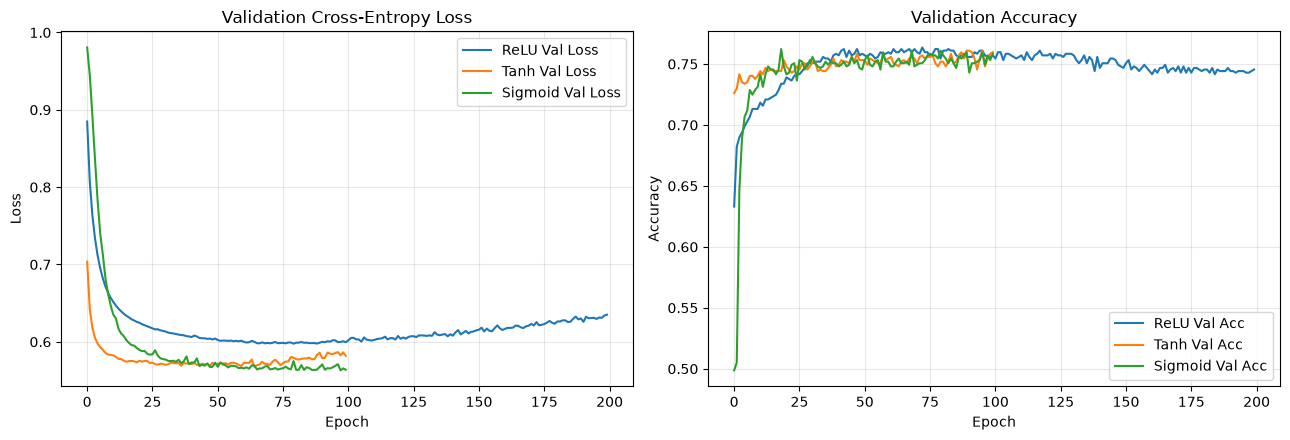

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, model in [('ReLU', ann_relu), ('Tanh', ann_tanh), ('Sigmoid', ann_sigmoid)]:
    axes[0].plot(model.history['val_loss'], label=f'{name} Val Loss')
    axes[1].plot(model.history['val_acc'], label=f'{name} Val Acc')

axes[0].set_title('Validation Cross-Entropy Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title('Validation Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()